Task was destroyed but it is pending!
task: <Task pending name='Task-129' coro=<_async_in_context.<locals>.run_in_context() done, defined at /Users/0x/dev/ml/projects/chatbot/.venv/lib/python3.14/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-130' coro=<Kernel.shell_main() running at /Users/0x/dev/ml/projects/chatbot/.venv/lib/python3.14/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /Users/0x/dev/ml/projects/chatbot/.venv/lib/python3.14/site-packages/zmq/eventloop/zmqstream.py:564]>
/Users/0x/dev/ml/projects/chatbot/.venv/lib/python3.14/site-packages/matplotlib/_api/__init__.py:250: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  or any(s != t and t is not None for s, t in zip(data_shape, shape))):
Task was destroyed but it is pending!
task: <Task pending name='Task-130' coro=<Kernel.shell_main() running at /Users/0x/dev/ml/projects/chatbot/.venv/lib/python3.14/site-pack

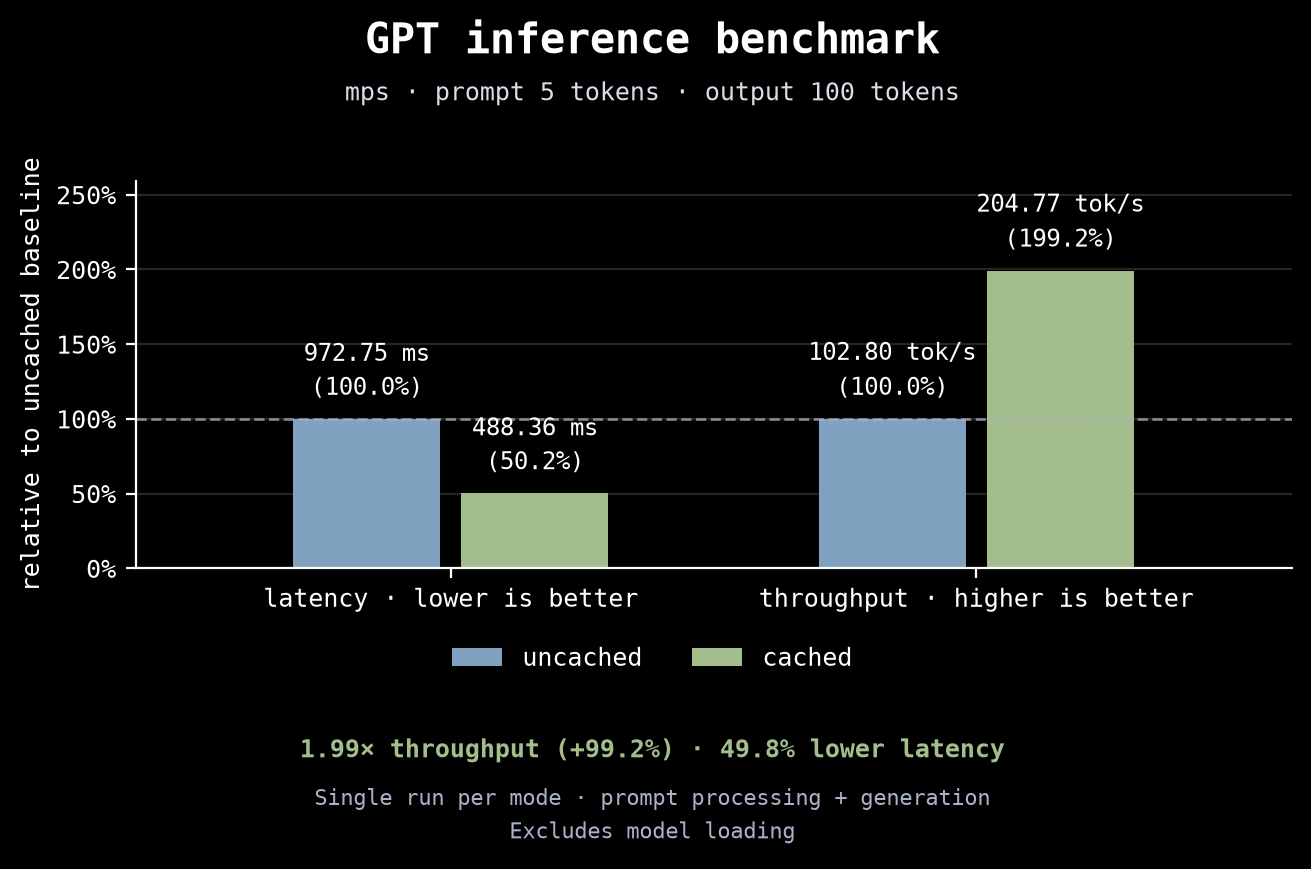

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
from matplotlib.ticker import PercentFormatter
from mlflow.tracking import MlflowClient

experiment_name = "kv-cache-comparison"
client = MlflowClient(tracking_uri="http://localhost:5001")
experiment = client.get_experiment_by_name(experiment_name)
if experiment is None:
    raise ValueError(f"Experiment not found: {experiment_name}")

runs = []
for enabled in ("False", "True"):
    matches = client.search_runs(
        [experiment.experiment_id],
        filter_string=f"params.use_cache = '{enabled}' AND attributes.status = 'FINISHED'",
        order_by=["attributes.start_time DESC"], max_results=1,
    )
    if not matches:
        raise ValueError(f"No completed run with use_cache={enabled}")
    runs.append(matches[0])

baseline, cached = runs
keys = ("checkpoint", "device", "prompt", "prompt_tokens", "output_tokens", "seed", "temperature")
if any(baseline.data.params.get(key) != cached.data.params.get(key) for key in keys):
    raise ValueError("The latest cached and uncached runs have different benchmark settings.")

latencies = [run.data.metrics["generation_time_ms"] for run in runs]
speeds = [run.data.metrics["output_tokens_per_second"] for run in runs]
params = cached.data.params
speedup = speeds[1] / speeds[0]
latency_gain = (1 - latencies[1] / latencies[0]) * 100

set_matplotlib_formats("retina")
plt.style.use("dark_background")
with plt.rc_context({"font.size": 9, "font.family": "monospace"}):
    fig, axis = plt.subplots(figsize=(6.8, 4.5))
    fig.patch.set_facecolor("#000000")
    for index, color, label in ((0, "#81a1c1", "uncached"), (1, "#a3be8c", "cached")):
        values = [latencies[index], speeds[index]]
        normalized = [values[0] / latencies[0] * 100, values[1] / speeds[0] * 100]
        positions = [-0.16 + index * 0.32, 0.84 + index * 0.32]
        bars = axis.bar(positions, normalized, width=0.28, color=color, label=label)
        axis.bar_label(bars, labels=[f"{value:,.2f} {unit}\n({percent:.1f}%)"
                       for value, unit, percent in zip(values, ("ms", "tok/s"), normalized)],
                       padding=5, fontsize=8.5, linespacing=1.5)
    axis.set_xticks([0, 1], ["latency · lower is better", "throughput · higher is better"])
    axis.set_xlim(-0.6, 1.6)
    axis.set_ylim(0, max(100, speedup * 100, 100 - latency_gain) * 1.3)
    axis.set_ylabel("relative to uncached baseline")
    axis.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    axis.axhline(100, color="#a9b1c6", linewidth=1, linestyle="--", alpha=0.7)
    axis.grid(axis="y", alpha=0.15)
    axis.set_axisbelow(True)
    axis.spines[["top", "right"]].set_visible(False)
    fig.legend(*axis.get_legend_handles_labels(), loc="lower center",
               bbox_to_anchor=(0.5, 0.22), ncol=2, frameon=False)
    fig.suptitle("GPT inference benchmark", fontsize=15, fontweight="bold", y=0.97)
    fig.text(0.5, 0.88, f"{params['device']} · prompt {params['prompt_tokens']} tokens · output {params['output_tokens']} tokens",
             ha="center", color="#d8dee9", fontsize=9)
    fig.text(0.5, 0.15, f"{speedup:.2f}× throughput (+{(speedup - 1) * 100:.1f}%) · {latency_gain:.1f}% lower latency",
             ha="center", color="#a3be8c", fontsize=9, fontweight="bold")
    fig.text(0.5, 0.06, "Single run per mode · prompt processing + generation\nExcludes model loading",
             ha="center", color="#a9b1c6", fontsize=8, linespacing=1.5)
    fig.subplots_adjust(left=0.12, right=0.97, top=0.79, bottom=0.36)
    plt.show()


In [10]:
root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "README.md").exists())
fig.savefig(root / "images/inference_benchmark.png", dpi=200, facecolor=fig.get_facecolor())
